In [1]:
import numpy as np 
import pandas as pd
import torch
import torch.nn as nn

In [2]:
df = pd.read_csv("11) Powerplant_dataset.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [ ]:
# AT => temperature
# V => vaccum
# AP => pressure
# RH => humidity
# PE => produced energy 


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
X = df.drop("PE",axis = 1)
Y = df["PE"]

In [6]:
X.head()

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


In [7]:
Y.head()


0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test = train_test_split(
    X, Y , test_size = 0.2 , random_state = 42
)


In [9]:
df.shape

(9568, 5)

In [10]:
# We are preprocessing the training and testing data through standard scaler.
from sklearn.preprocessing import StandardScaler
std = StandardScaler()
X_train_scaled = std.fit_transform(X_train)
X_test_scaled = std.transform(X_test)


In [11]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [12]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [27]:
# Converting the X_train, Y_train,X_test,Y_test into tensors:=>
X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype = torch.float32)
Y_train_tensor = torch.tensor(Y_train.values,dtype = torch.float32).view(-1,1)
Y_test_tensor = torch.tensor(Y_test.values,dtype = torch.float32).view(-1,1)

In [28]:
# Creating our dataset class as well as the dataloader class
from torch.utils.data import DataLoader, TensorDataset 
train_Dataset = TensorDataset(X_train_tensor, Y_train_tensor)
test_Dataset = TensorDataset(X_test_tensor, Y_test_tensor)

In [29]:
train_Loader = DataLoader(train_Dataset,batch_size = 32,shuffle = True)
test_Loader = DataLoader(test_Dataset,batch_size = 32, shuffle = True)

In [30]:
train_Loader

In [31]:
test_Loader

# Deep Learning


In [32]:
# Build an ANN model:=>
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        self.model = nn.Sequential(
        # 1st hidden layer
        nn.Linear(X_train.shape[1],6),
        nn.ReLU(),
        # 2nd hidden layer
        nn.Linear(6,6),
        nn.ReLU(),
        # Output Layer
        nn.Linear(6,1)
    )
    def forward(self,x):
        return self.model(x)

    

In [33]:
import torch.optim as optim
model = ANN()
# loss, optimiser
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters() , lr =0.01)

In [34]:
# Train a model:=>
train_losses =[]
val_losses = []
best_val_loss = float("inf")
epochs = 100 
for  epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch
    for xb, yb in train_Loader:
        # xb is features of 1st batch.
        # yb is alabel of 1st batch.
       optimizer.zero_grad()
        
       outputs =  model(xb) # forward propagation predicted outputs from this batch
       loss  = crietrion(outputs,yb) # compute loss
       loss.backward() # back propagation
       optimizer.step() # parameters update.
       running_loss += loss.item() # loss is tensor and we are converting into python float 
    epoch_train_loss = running_loss/ len(train_Loader)
    train_losses.append(epoch_train_loss)
    # validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad(): # no gradients computations takes place.
        for xb,yb in test_Loader:
            outputs = model(xb)
            loss = crietrion(outputs,yb)
            running_val_loss += loss 
    epoch_val_loss = running_val_loss / len(test_Loader)
    val_losses.append(epoch_val_loss)
    print(f"epoch ${epoch+1}/{epochs} ==> train loss = ${epoch_train_loss} $ val loss => ${epoch_val_loss}")
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") # .pt or .pth
        
    
        
    


epoch $1/100 ==> train loss = $87678.82028605143 $ val loss => $7529.03173828125
epoch $2/100 ==> train loss = $2278.0583686828613 $ val loss => $342.98974609375
epoch $3/100 ==> train loss = $156.86192452112834 $ val loss => $73.8233642578125
epoch $4/100 ==> train loss = $50.59923657576243 $ val loss => $34.37428665161133
epoch $5/100 ==> train loss = $31.008946444590887 $ val loss => $25.179584503173828
epoch $6/100 ==> train loss = $25.28246724208196 $ val loss => $21.632131576538086
epoch $7/100 ==> train loss = $23.355587045351665 $ val loss => $20.6251220703125
epoch $8/100 ==> train loss = $22.40400248368581 $ val loss => $20.298309326171875
epoch $9/100 ==> train loss = $21.84620506167412 $ val loss => $19.982641220092773
epoch $10/100 ==> train loss = $21.95711443424225 $ val loss => $20.7175235748291
epoch $11/100 ==> train loss = $21.703987848758697 $ val loss => $19.791614532470703
epoch $12/100 ==> train loss = $21.729195034503938 $ val loss => $20.45497703552246
epoch $1

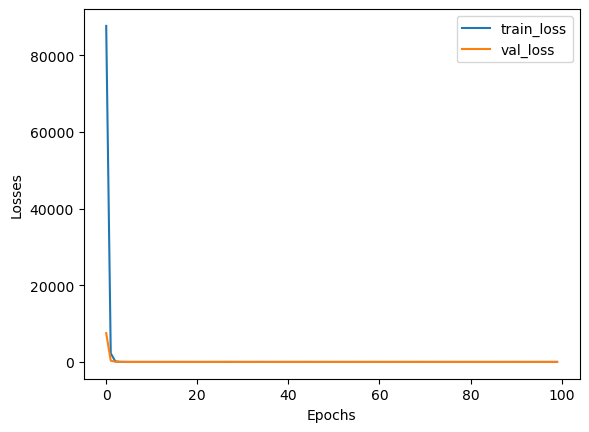

In [35]:
# plot these all losses in a plot:=>
import matplotlib.pyplot as plt 
loss_df = pd.DataFrame({
    "train_loss": train_losses,
    "val_loss": val_losses
})
plt.plot(loss_df["train_loss"], label = "train_loss")
plt.plot(loss_df["val_loss"],label = "val_loss")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [36]:
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [37]:
# Evaluation:=>
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)
    train_mse_loss = crietrion(train_preds,Y_train_tensor)
    test_mse_loss = crietrion(test_preds,Y_test_tensor)
print("Training MSE:",train_mse_loss.item())
print("Testing MSE:",test_mse_loss.item())

Training MSE: 19.88115119934082
Testing MSE: 18.348569869995117


In [39]:
from sklearn.metrics import r2_score
print("r2_score:", r2_score(Y_test, test_preds))

r2_score: 0.9358764829437525
